# Understanding PRISM drug-response data

**Goal:** understand the experimental units and audit the joins before modeling. Each outcome is a cell-line–treatment measurement, not a patient outcome.

This walkthrough uses the local files documented in `data/raw/README.md`. Run cells in order.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/data_manifest.json").exists())
RAW = ROOT / "data/raw"
responses = pd.read_csv(RAW / "primary-screen-replicate-collapsed-logfold-change.csv", index_col=0)
cells = pd.read_csv(RAW / "primary-screen-cell-line-info.csv")
treatments = pd.read_csv(RAW / "primary-screen-replicate-collapsed-treatment-info.csv")
samples = pd.read_csv(RAW / "sample_info.csv")

## 1. What is in each table?

The response matrix has cell lines on rows and treatment conditions on columns. The other tables describe those identifiers.

In [2]:
display(pd.DataFrame({"table": ["responses", "screen cells", "treatments", "DepMap samples"], "rows": [len(t) for t in [responses,cells,treatments,samples]], "columns": [t.shape[1] for t in [responses,cells,treatments,samples]]}))
display(responses.iloc[:5, :5])
display(treatments.head(3))

,table,rows,columns
0,responses,578,4686
1,screen cells,588,10
2,treatments,4686,11
3,DepMap samples,1825,26


,BRD-A00077618-236-07-6::2.5::HTS,BRD-A00100033-001-08-9::2.5::HTS,BRD-A00147595-001-01-5::2.5::HTS,BRD-A00218260-001-03-4::2.5::HTS,BRD-A00376169-001-01-6::2.5::HTS
ACH-000001,-0.015577,-0.449332,0.489379,0.206675,0.272730
ACH-000007,-0.095730,0.257943,0.772349,-0.438502,-0.732832
ACH-000008,0.379480,-0.596132,0.548056,0.422269,-0.216986
ACH-000010_FAILED_STR,0.118890,-0.231615,0.621937,-0.202707,-1.005139
ACH-000011,0.145346,-0.499274,0.267470,0.157804,-0.272286


,column_name,broad_id,name,dose,screen_id,moa,target,disease.area,indication,smiles,phase
0,BRD-A00055058-001-01-0::2.325889319::MTS004,BRD-A00055058-001-01-0,RS-0481,2.325889,MTS004,immunostimulant,NaN,NaN,NaN,CC(NC(=O)C1CSCN1C(=O)c1ccccc1)c1ccccc1,Phase 2
1,BRD-A00842753-001-01-9::2.5::MTS004,BRD-A00842753-001-01-9,oleuropein,2.500000,MTS004,estrogen receptor agonist,GPER1,NaN,NaN,COC(=O)C1=COC(OC2OC(CO)C(O)C(O)C2O)\C(=C/C)C1C...,Phase 2
2,BRD-A02232681-001-01-8::2.5::MTS004,BRD-A02232681-001-01-8,isoleucine,2.500000,MTS004,NaN,"ACADSB, BCAT1, BCAT2, IARS, IARS2",NaN,NaN,CCC(C)C(N)C(O)=O,Launched


## 2. Validate relationships

Join by IDs, never by row position. A failed identity must not be mapped back to its original, unconfirmed name.

In [3]:
assert responses.index.is_unique and responses.columns.is_unique
assert cells.row_name.is_unique
assert treatments.column_name.is_unique
assert samples.DepMap_ID.is_unique
assert responses.index.isin(cells.row_name).all()
assert responses.columns.isin(treatments.column_name).all()

screen_cells = cells.set_index("row_name").loc[responses.index].copy()
passed = screen_cells.passed_str_profiling.astype(str).str.lower().eq("true")
verified = screen_cells.depmap_id.notna() & passed
assert screen_cells.loc[verified, "depmap_id"].isin(samples.DepMap_ID).all()
print(f"Verified cells: {verified.sum()} / {len(verified)}")
display(screen_cells.loc[~verified, ["depmap_id", "passed_str_profiling", "str_profiling_notes"]])

Verified cells: 568 / 578


,depmap_id,passed_str_profiling,str_profiling_notes
ACH-000010_FAILED_STR,NaN,False,STR matches to NCI-H1581 (known misidentified ...
ACH-000028_FAILED_STR,NaN,False,STR matches MCF7 (known misidentified)
ACH-000409_FAILED_STR,NaN,False,"STR does not match profile, missidentified (ST..."
ACH-000460_FAILED_STR,NaN,False,"STR does not match profile, missidentified"
ACH-000511_FAILED_STR,NaN,False,STR matches R1192/Caki1
ACH-000539_FAILED_STR,NaN,False,STR profile matches cell line SW569
ACH-000807_FAILED_STR,NaN,False,STR shows cross contamination with TOM1 and po...
ACH-000925_FAILED_STR,NaN,False,STR matches LS180
ACH-000992_FAILED_STR,NaN,False,STR shows mouse contamination
ACH-001078_FAILED_STR,NaN,False,STR matches cell line LS513


## 3. Quantify missing responses

Keep missing outcomes missing. We will later examine whether missingness differs by screen or cell type.

In [4]:
missing = int(responses.isna().sum().sum())
observed = int(responses.notna().sum().sum())
display(pd.Series({"possible responses": responses.size, "observed": observed, "missing": missing, "missing fraction": missing / responses.size}))

possible responses    2.708508e+06
observed              2.632171e+06
missing               7.633700e+04
missing fraction      2.818415e-02
dtype: float64

## 4. Trace one treatment across cells

Use the first treatment as an illustrative example, not as a modeling target chosen for its results. Negative values indicate lower relative viability signal. This is not a clinical efficacy estimate.

In [5]:
treatment_id = responses.columns[0]
treatment = treatments.set_index("column_name").loc[treatment_id]
display(treatment)
example = responses[treatment_id].rename("log_fold_change").to_frame().join(screen_cells[["depmap_id"]])
example = example.loc[verified].merge(samples[["DepMap_ID", "cell_line_name", "lineage"]], left_on="depmap_id", right_on="DepMap_ID", how="left", validate="many_to_one")
display(example.head())

broad_id                                   BRD-A00077618-236-07-6
name                                                 8-bromo-cGMP
dose                                                          2.5
screen_id                                                     HTS
moa                                                 PKA activator
target                                                      PRKG1
disease.area                                                  NaN
indication                                                    NaN
smiles          Nc1nc(O)c2nc(Br)n([C@@H]3O[C@@H]4COP(O)(=O)O[C...
phase                                                 Preclinical
Name: BRD-A00077618-236-07-6::2.5::HTS, dtype: object

,log_fold_change,depmap_id,DepMap_ID,cell_line_name,lineage
0,-0.015577,ACH-000001,ACH-000001,NIH:OVCAR-3,ovary
1,-0.095730,ACH-000007,ACH-000007,LS513,colorectal
2,0.379480,ACH-000008,ACH-000008,A101D,skin
3,0.145346,ACH-000011,ACH-000011,253J,urinary_tract
4,0.103348,ACH-000012,ACH-000012,HCC827,lung


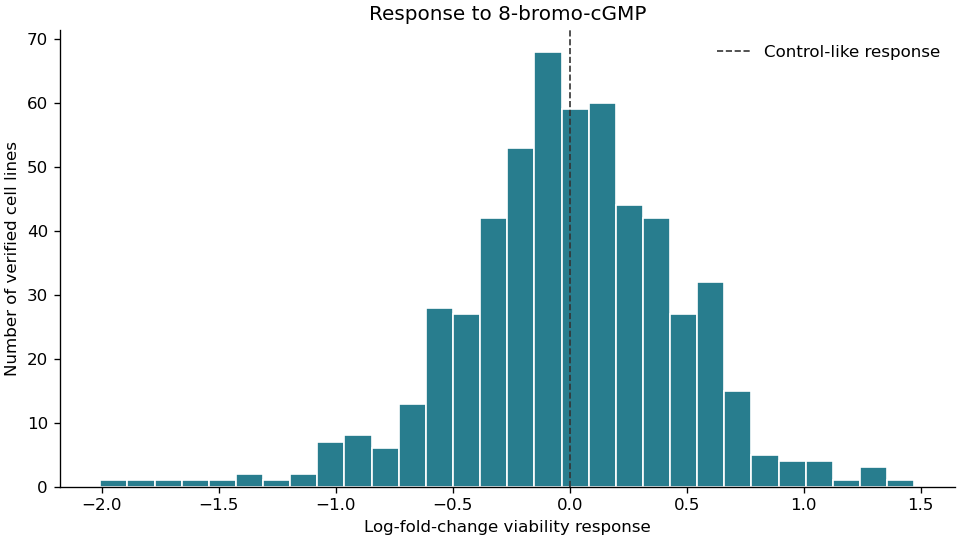

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(example.log_fold_change.dropna(), bins=30, color="#287D8E", edgecolor="white")
ax.axvline(0, color="#333333", linestyle="--", linewidth=1, label="Control-like response")
ax.set(title=f"Response to {treatment["name"]}", xlabel="Log-fold-change viability response", ylabel="Number of verified cell lines")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(ROOT / "reports/figures/example_treatment_response.png", dpi=180)
plt.show()

## Your interpretation

Before adding models, write your own observations here:

- What does one point in this dataset represent?
- Why are the failed identity rows excluded?
- What does the shape of the example distribution suggest?
- What cannot be concluded from this plot?

**Next:** compare treatment coverage and response distributions, then explore cancer-type patterns. Molecular features and modeling will follow a defined prediction question.